# Task 2 — Yelp Polarity sentiment classification (no pretrained embeddings / LMs)

**DATA 266 · Lab 1** · Three models are trained per member (one Baseline + two Experimental),
all with **word embeddings learned from scratch** (`nn.Embedding`, randomly initialised).

Notebook map
1. Setup (member, config, seed, raw log, hardware)
2. **2.1 Data preprocessing** — EDA (length / class distribution / balance), missing & malformed entries,
   lowercasing, punctuation removal, stopword removal (negations kept), lemmatisation or stemming, tokenisation, vocabulary, fixed-length encoding
3. **2.2 Models** — definitions + justification, training, exact CPU/GPU recorded per model
4. Evaluation with the team's shared `eval_task2.py` — every metric in the brief, bootstrap CIs, McNemar, slices
5. **Error review** of 20 errors (5 confident FP, 5 confident FN, 5 near-threshold, 5 slice-specific)
6. **2.3 Comparison** of this member's models → `metrics_report.csv`, `results.md`, manifest

In [1]:
MEMBER = "ruchika_chaurasia"   # <-- the only line that differs between member notebooks
TASK = "task2_sentiment"

import importlib.util, os, subprocess, sys
from pathlib import Path

for pkg, mod in [("datasets", "datasets"), ("pyyaml", "yaml"), ("nltk", "nltk")]:
    if importlib.util.find_spec(mod) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

def _find_root():
    if os.environ.get("REPO_ROOT"):
        return Path(os.environ["REPO_ROOT"]).resolve()
    here = Path.cwd().resolve()
    for q in [here, *here.parents]:
        if (q / "README.md").exists() and (q / "task1_llm").is_dir():
            return q
    raise FileNotFoundError("cd into the repo folder first (the one containing README.md)")

REPO_ROOT = _find_root()
sys.path.insert(0, str(REPO_ROOT))
sys.path.insert(0, str(REPO_ROOT / TASK / "common"))

In [2]:
import json, math, re, time, copy
from collections import Counter
from functools import lru_cache
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, roc_curve, precision_recall_curve

from common.runtime import (RawLogger, Timer, get_device, hardware_info, is_smoke, load_config,
                            peak_memory_mb, personal_params, reset_peak_memory, set_seed,
                            write_manifest, file_sha)
import eval_task2 as E

CFG = load_config(REPO_ROOT / TASK / MEMBER / "config.yaml")
if CFG.get("sid4") is not None:
    PP = personal_params(int(CFG["sid4"]))
    SID4, SEED, SLICE, HP_ID, CLS_A, CLS_B = (PP[k] for k in ["SID4", "SEED", "SLICE", "HP_ID", "CLS_A", "CLS_B"])
    print(f"SID4={SID4}  SEED={SEED}  SLICE={SLICE}  HP_ID={HP_ID}  CLS_A={CLS_A}  CLS_B={CLS_B}")
SEED = int(CFG["seed"])

if is_smoke():
    CFG["data"].update(train_size=3000, val_size=500, test_size=1000)
    for m in CFG["models"]:
        m.update(epochs=1)
    E.N_BOOT = 50

OUT_ROOT = (REPO_ROOT / "_smoke" / TASK / MEMBER) if is_smoke() else (REPO_ROOT / TASK / MEMBER)
DIRS = {k: OUT_ROOT / k for k in ["data_processed", "checkpoints", "outputs"]}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)

set_seed(SEED)
device = get_device()
log = RawLogger(REPO_ROOT, TASK, MEMBER)
HW = hardware_info()
HW_STR = f"GPU: {HW.get('gpu')} | CPU: {HW['cpu']} ({HW['cpu_count']} cores)"
log("member:", MEMBER, "| lineup:", CFG.get("lineup"), "| seed:", SEED, "| smoke:", is_smoke())
log("hardware:", HW_STR)
log("config:", json.dumps(CFG))

SID4=8283  SEED=8283  SLICE=283  HP_ID=3  CLS_A=3  CLS_B=4
raw log started: reproducibility/raw_logs/task2_sentiment_ruchika_chaurasia_20261002_000303.log
member: ruchika_chaurasia | lineup: A | seed: 8283 | smoke: False
hardware: GPU: NVIDIA GeForce RTX 5090 | CPU: Intel(R) Core(TM) Ultra 9 285K (24 cores)
config: {"member": "ruchika_chaurasia", "lineup": "A", "sid4": 8283, "seed": 8283, "data": {"hf_name": "fancyzhx/yelp_polarity", "local_csv_dir": null, "train_size": 200000, "val_size": 20000, "test_size": null}, "preprocess": {"lowercase": true, "remove_stopwords": true, "keep_negations": true, "normalizer": "lemmatize", "max_vocab": 40000, "min_freq": 3, "max_len": 256, "truncation": "head_tail"}, "review_model": null, "models": [{"name": "A_baseline_embbag", "role": "baseline", "type": "embbag", "emb_dim": 100, "ngram": 1, "hidden": 0, "dropout": 0.2, "lr": 0.005, "weight_decay": 0.0, "batch_size": 512, "epochs": 5, "patience": 2, "why": "Bag of learned word embeddings (fastText-

## 2.1 Data preprocessing
### Load the data
Yelp Polarity: 560,000 train and 38,000 test reviews. Label 0 = negative (1–2 stars), 1 = positive (4–5 stars).
The **official test split is used untouched** for final evaluation. The train split is cleaned, then a
stratified subset (`train_size` + `val_size`) is drawn with this member's seed. Validation is used only
for model and epoch selection.

In [3]:
def load_raw():
    dc = CFG["data"]
    if dc.get("local_csv_dir"):   # fallback: fast.ai CSVs (no header; label 1=neg, 2=pos)
        d = REPO_ROOT / dc["local_csv_dir"]
        tr = pd.read_csv(d / "train.csv", header=None, names=["label", "text"])
        te = pd.read_csv(d / "test.csv", header=None, names=["label", "text"])
        tr["label"], te["label"] = tr["label"] - 1, te["label"] - 1
        return tr, te
    from datasets import load_dataset
    try:
        ds = load_dataset(dc["hf_name"])
    except Exception as err:
        log("primary dataset name failed, trying 'yelp_polarity':", err)
        ds = load_dataset("yelp_polarity")
    return ds["train"].to_pandas(), ds["test"].to_pandas()

with Timer() as t_load:
    train_df, test_df = load_raw()
log(f"raw train {len(train_df):,} | raw test {len(test_df):,} | loaded in {t_load.seconds:.0f}s")
train_df.head()

/opt/conda/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Generating test split: 100%|██████████| 38000/38000 [00:00<00:00, 837067.71 examples/s]


raw train 560,000 | raw test 38,000 | loaded in 12s


,text,label
0,"Unfortunately, the frustration of being Dr. Go...",0
1,Been going to Dr. Goldberg for over 10 years. ...,1
2,I don't know what Dr. Goldberg was like before...,0
3,I'm writing this review to give you a heads up...,0
4,All the food is great here. But the best thing...,1


### Missing values and malformed entries
Checks: null / non-string text, empty or whitespace-only reviews, labels outside {0, 1}, escaped
line breaks (`\n` stored literally as backslash-n in this dataset), exact duplicates, and train/test
overlap (the same review in both splits would leak test information).

In [4]:
def audit(df, name):
    s = df["text"]
    rep = {"split": name, "rows": len(df),
           "null_text": int(s.isna().sum()),
           "non_string": int((~s.map(lambda v: isinstance(v, str))).sum()),
           "empty_or_blank": int(s.fillna("").str.strip().eq("").sum()),
           "bad_label": int((~df["label"].isin([0, 1])).sum()),
           "literal_backslash_n": int(s.fillna("").str.contains(r"\\n", regex=False).sum()),
           "duplicate_texts": int(s.duplicated().sum())}
    return rep

audit_before = pd.DataFrame([audit(train_df, "train"), audit(test_df, "test")])
print(audit_before.to_string(index=False))

def fix_text(t):
    return re.sub(r"\s+", " ", t.replace("\\n", " ").replace('\\"', '"')).strip()

for df in (train_df, test_df):
    df.dropna(subset=["text", "label"], inplace=True)
    df["text"] = df["text"].astype(str).map(fix_text)
    df.drop(df[df["text"].eq("") | ~df["label"].isin([0, 1])].index, inplace=True)
n0 = len(train_df)
train_df = train_df.drop_duplicates("text")
overlap = train_df["text"].isin(set(test_df["text"]))
train_df = train_df[~overlap].reset_index(drop=True)
test_df = test_df.reset_index(drop=True)
log(f"cleaning: removed {n0 - len(train_df) - int(overlap.sum()):,} duplicate train rows and "
    f"{int(overlap.sum()):,} train rows that also appear in test; train now {len(train_df):,}")
if CFG["data"].get("test_size"):
    test_df = test_df.sample(n=CFG["data"]["test_size"], random_state=SEED).reset_index(drop=True)

split   rows  null_text  non_string  empty_or_blank  bad_label  literal_backslash_n  duplicate_texts
train 560000          0           0               0          0                   49                0
 test  38000          0           0               0          0                    4                0
cleaning: removed 49 duplicate train rows and 10 train rows that also appear in test; train now 559,941


### Exploratory analysis — length distribution, class distribution, balance

                                 train     test
negative (0)             279951.000000  19000.0
positive (1)             279990.000000  19000.0
balance ratio (min/max)       0.999861      1.0

words per review (train):
          count   mean    std  min   25%    50%    75%     max
label                                                         
0      279951.0  152.6  136.7  1.0  60.0  112.0  199.0  1052.0
1      279990.0  115.5  105.9  1.0  44.0   85.0  152.0  1010.0


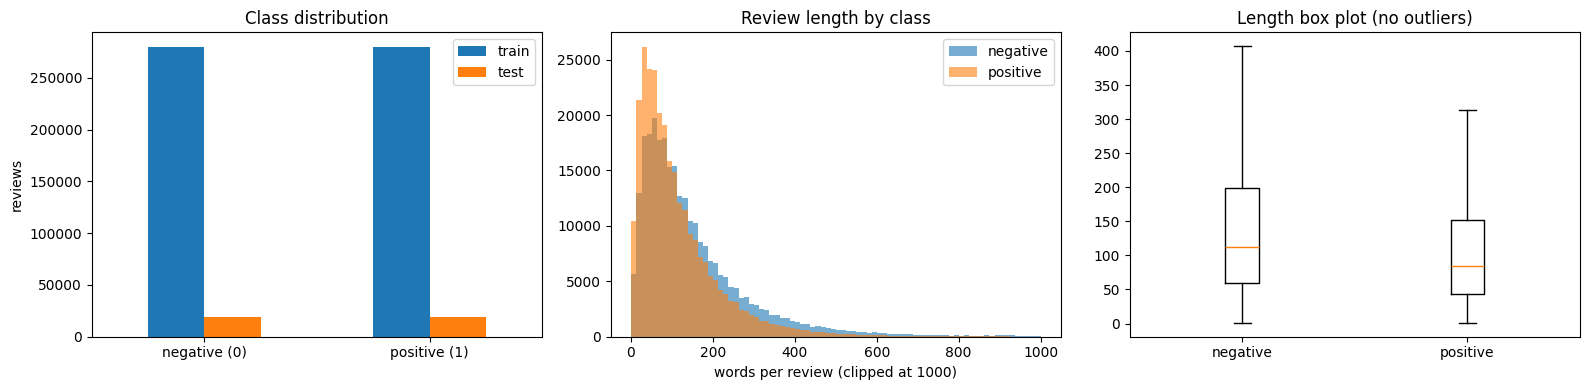

length percentiles (words) 50/90/95/99: [98.0, 284.0, 375.0, 613.0] | classes are balanced (ratio 1.000) so accuracy is meaningful; macro-F1 and MCC are still reported


In [5]:
for df in (train_df, test_df):
    df["n_words"] = df["text"].str.split().map(len)
dist = pd.DataFrame({"train": train_df["label"].value_counts().sort_index(),
                     "test": test_df["label"].value_counts().sort_index()})
dist.index = ["negative (0)", "positive (1)"]
dist.loc["balance ratio (min/max)"] = [dist.iloc[:2, i].min() / dist.iloc[:2, i].max() for i in range(2)]
print(dist)
print("\nwords per review (train):")
print(train_df.groupby("label")["n_words"].describe().round(1))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
dist.iloc[:2].plot.bar(ax=ax[0], rot=0); ax[0].set_title("Class distribution"); ax[0].set_ylabel("reviews")
for lab, name in [(0, "negative"), (1, "positive")]:
    ax[1].hist(train_df.loc[train_df.label == lab, "n_words"].clip(upper=1000), bins=80, alpha=0.6, label=name)
ax[1].set_xlabel("words per review (clipped at 1000)"); ax[1].set_title("Review length by class"); ax[1].legend()
ax[2].boxplot([train_df.loc[train_df.label == l, "n_words"] for l in (0, 1)], showfliers=False)
ax[2].set_xticklabels(["negative", "positive"]); ax[2].set_title("Length box plot (no outliers)")
plt.tight_layout(); plt.savefig(DIRS["outputs"] / "eda_length_class.png", dpi=120); plt.show()
q = np.percentile(train_df["n_words"], [50, 90, 95, 99])
log(f"length percentiles (words) 50/90/95/99: {q.round(0).tolist()} | classes are balanced "
    f"(ratio {dist.iloc[2, 0]:.3f}) so accuracy is meaningful; macro-F1 and MCC are still reported")

In [6]:
dc = CFG["data"]
tr_part, rest = train_test_split(train_df, train_size=dc["train_size"], stratify=train_df["label"], random_state=SEED)
va_part, _ = train_test_split(rest, train_size=dc["val_size"], stratify=rest["label"], random_state=SEED)
tr_part, va_part = tr_part.reset_index(drop=True), va_part.reset_index(drop=True)
log(f"subset: train {len(tr_part):,} | val {len(va_part):,} | test {len(test_df):,} (seed {SEED})")

subset: train 200,000 | val 20,000 | test 38,000 (seed 8283)


### Text preprocessing
1. lowercase
2. expand contractions (`didn't` → `did not`) **before** removing punctuation, so negations survive
3. remove URLs, punctuation, digits, and special characters
4. remove English stopwords, **except** negations and intensity/contrast words (`not`, `no`, `never`,
   `but`, `very`, `too`, `only` …). The standard NLTK list deletes `not`, which would turn
   "not good" into "good" — fatal for sentiment.
5. lemmatise (WordNet, verb then noun) **or** stem (Porter), set per member in the config
6. tokenise on whitespace

In [7]:
import nltk
for pkg in ["stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer, PorterStemmer

PC = CFG["preprocess"]
KEEP = {"no", "not", "nor", "never", "but", "very", "too", "only", "against", "few", "more", "most", "over",
        "off", "don", "didn", "doesn", "isn", "wasn", "weren", "won", "wouldn", "shouldn", "couldn", "aren", "hasn", "haven"}
STOP = set(stopwords.words("english")) - (KEEP if PC["keep_negations"] else set())
CONTRACTIONS = [(r"\bwon't\b", "will not"), (r"\bcan't\b", "can not"), (r"n't\b", " not"), (r"'re\b", " are"),
                (r"'ll\b", " will"), (r"'ve\b", " have"), (r"'m\b", " am"), (r"'d\b", " would"), (r"'s\b", "")]
_lem, _stem = WordNetLemmatizer(), PorterStemmer()

@lru_cache(maxsize=500_000)
def normalise(w):
    if PC["normalizer"] == "lemmatize":
        return _lem.lemmatize(_lem.lemmatize(w, "v"), "n")
    if PC["normalizer"] == "stem":
        return _stem.stem(w)
    return w

def preprocess(text):
    t = text.lower() if PC["lowercase"] else text
    t = t.replace("\u2019", "'")
    for pat, rep in CONTRACTIONS:
        t = re.sub(pat, rep, t)
    t = re.sub(r"https?://\S+|www\.\S+", " ", t)
    t = re.sub(r"[^a-z\s]", " ", t)          # punctuation, digits, special characters
    toks = [w for w in t.split() if len(w) > 1 or w in ("i", "a")]
    if PC["remove_stopwords"]:
        toks = [w for w in toks if w not in STOP]
    return [normalise(w) for w in toks]

for s in tr_part["text"].head(3):
    print("RAW :", s[:200]); print("PROC:", " ".join(preprocess(s))[:200]); print()

RAW : This place has been so wonderful to us, since we discovered them after our beloved cat broke her leg following a grooming incident. We only have her groomed here from now on under the watchful eye of 
PROC: place wonderful u since discover beloved cat break leg follow groom incident only groom watchful eye vet wonderful staff groomers get care delight everything place include dr moses only vet would reco

RAW : I've only been once but it was enough for me to form my opinion. I'm not one for kitsch and this place is full of it. I should have turned around and left when they pulled the door stunt, but I didn't
PROC: only but enough form opinion not one kitsch place full turn around leave pull door stunt but not watch step enter too place dark need flash light see anything shoulda run finally get seat greated serv

RAW : This is probably one of the most disappointing buffets I have had in Vegas. They charge brunch prices for breakfast. No crab legs, no shrimp...the food looks less t

In [8]:
def run_preprocess(texts):
    try:
        from multiprocessing import Pool
        with Pool(max(1, os.cpu_count() or 1)) as pool:
            return pool.map(preprocess, texts, chunksize=2000)
    except Exception as err:                  # e.g. spawn-only platforms: fall back to serial
        log("multiprocessing unavailable, running serially:", err)
        return [preprocess(t) for t in texts]

cache = DIRS["data_processed"] / f"tokens_{SEED}_{PC['normalizer']}_{len(tr_part)}_{len(va_part)}_{len(test_df)}.pkl"
with Timer() as t_pp:
    if cache.exists() and not is_smoke():
        tok_tr, tok_va, tok_te = pd.read_pickle(cache)
    else:
        tok_tr, tok_va, tok_te = (run_preprocess(d["text"].tolist()) for d in (tr_part, va_part, test_df))
        pd.to_pickle((tok_tr, tok_va, tok_te), cache)
log(f"preprocessing done in {t_pp.seconds:.0f}s")

preprocessing done in 5s


### Vocabulary and fixed-length encoding
The vocabulary is built from the **training subset only** (no peeking at val/test): the `max_vocab` most
frequent tokens with frequency ≥ `min_freq`. Index 0 = `<pad>`, 1 = `<unk>`. Reviews are cut or padded to
`max_len` tokens. `head_tail` truncation keeps the first and last halves, because Yelp reviewers often
state their verdict at the end.

In [9]:
cnt = Counter(w for toks in tok_tr for w in toks)
itos = ["<pad>", "<unk>"] + [w for w, c in cnt.most_common(PC["max_vocab"]) if c >= PC["min_freq"]]
stoi = {w: i for i, w in enumerate(itos)}
V = len(itos)
L = PC["max_len"]

def encode(toks):
    ids = [stoi.get(w, 1) for w in toks] or [1]
    if len(ids) > L:
        ids = ids[: L // 2] + ids[-(L - L // 2):] if PC["truncation"] == "head_tail" else ids[:L]
    return ids

def to_tensor(tok_lists):
    X = np.zeros((len(tok_lists), L), dtype=np.int64)
    lens = np.zeros(len(tok_lists), dtype=np.int64)
    for i, toks in enumerate(tok_lists):
        ids = encode(toks); X[i, :len(ids)] = ids; lens[i] = len(ids)
    return torch.from_numpy(X), torch.from_numpy(lens)

Xtr, Ltr = to_tensor(tok_tr); Xva, Lva = to_tensor(tok_va); Xte, Lte = to_tensor(tok_te)
ytr = torch.tensor(tr_part["label"].values, dtype=torch.float32)
yva = torch.tensor(va_part["label"].values, dtype=torch.float32)
yte_np = test_df["label"].values.astype(int)
(DIRS["data_processed"] / "vocab.json").write_text(json.dumps(itos))

tok_lens = np.array([len(t) for t in tok_tr])
oov_te = np.mean([np.mean([w not in stoi for w in t]) if t else 0 for t in tok_te])
log(f"vocab size {V:,} | tokens/review after preprocessing: median {np.median(tok_lens):.0f}, "
    f"95th pct {np.percentile(tok_lens, 95):.0f} | truncated at {L}: {(tok_lens > L).mean():.1%} of train reviews | test OOV rate {oov_te:.2%}")

vocab size 39,449 | tokens/review after preprocessing: median 52, 95th pct 196 | truncated at 256: 2.2% of train reviews | test OOV rate 0.65%


## 2.2 Models
Every model starts with `nn.Embedding(V, d, padding_idx=0)` initialised randomly, so the embeddings are
**learned from scratch** jointly with the classifier. No pretrained vectors or language models are used.
All models output one logit and are trained with `BCEWithLogitsLoss`, so P(positive) = sigmoid(logit).

| type | idea | why it is in the bake-off |
|---|---|---|
| `embbag` | average of word (+ optional hashed bigram) embeddings → linear | fastText-style baseline: fast, strong on polarity; ignores word order (bigrams recover some, e.g. "not good") |
| `textcnn` | parallel 1-D convolutions (widths 3/4/5) + max-over-time pooling | detects local n-gram patterns ("not worth", "highly recommend") regardless of position |
| `bilstm_attn` | bidirectional LSTM + additive attention pooling | models word order and long-range context; attention weights show which words drove the decision |
| `bigru_max` | 2-layer bidirectional GRU + max pooling | a lighter recurrent cell than the LSTM; max pooling keeps the strongest signal |
| `transformer` | small Transformer encoder (learned positions) + masked mean pooling | self-attention sees every word pair directly; tests whether that helps without pretraining |

In [10]:
class EmbBag(nn.Module):
    def __init__(self, V, emb_dim, ngram=1, buckets=0, hidden=0, dropout=0.2, **_):
        super().__init__()
        self.V, self.ngram, self.buckets = V, ngram, buckets
        self.emb = nn.Embedding(V + (buckets if ngram == 2 else 0), emb_dim, padding_idx=0)
        self.drop = nn.Dropout(dropout)
        self.head = (nn.Sequential(nn.Linear(emb_dim, hidden), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden, 1))
                     if hidden else nn.Linear(emb_dim, 1))

    def forward(self, x, lengths):
        mask = (x != 0).unsqueeze(-1).float()
        tot, cnt = (self.emb(x) * mask).sum(1), mask.sum(1)
        if self.ngram == 2:                                   # hashed bigram embeddings
            bi = self.V + (x[:, :-1] * 1_000_003 + x[:, 1:]) % self.buckets
            bmask = (mask[:, :-1] * mask[:, 1:])
            tot, cnt = tot + (self.emb(bi) * bmask).sum(1), cnt + bmask.sum(1)
        return self.head(self.drop(tot / cnt.clamp(min=1))).squeeze(-1)


class TextCNN(nn.Module):
    def __init__(self, V, emb_dim, kernels=(3, 4, 5), filters=100, dropout=0.5, **_):
        super().__init__()
        self.emb = nn.Embedding(V, emb_dim, padding_idx=0)
        self.convs = nn.ModuleList([nn.Conv1d(emb_dim, filters, k, padding=k // 2) for k in kernels])
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(filters * len(kernels), 1)

    def forward(self, x, lengths):
        e = self.emb(x).transpose(1, 2)                                   # (B, d, L)
        mask = (x != 0).unsqueeze(1)
        pooled = []
        for conv in self.convs:
            h = F.relu(conv(e))[:, :, : x.size(1)]
            pooled.append(h.masked_fill(~mask, 0).max(dim=2).values)       # max over time, pads ignored
        return self.fc(self.drop(torch.cat(pooled, 1))).squeeze(-1)


class BiLSTMAttn(nn.Module):
    def __init__(self, V, emb_dim, hidden=128, layers=1, dropout=0.3, **_):
        super().__init__()
        self.emb = nn.Embedding(V, emb_dim, padding_idx=0)
        self.drop = nn.Dropout(dropout)
        self.lstm = nn.LSTM(emb_dim, hidden, num_layers=layers, bidirectional=True, batch_first=True,
                            dropout=dropout if layers > 1 else 0.0)
        self.att_w = nn.Linear(2 * hidden, 2 * hidden)
        self.att_v = nn.Linear(2 * hidden, 1, bias=False)
        self.fc = nn.Linear(2 * hidden, 1)

    def forward(self, x, lengths, return_attention=False):
        e = self.drop(self.emb(x))
        packed = nn.utils.rnn.pack_padded_sequence(e, lengths.cpu(), batch_first=True, enforce_sorted=False)
        H, _ = nn.utils.rnn.pad_packed_sequence(self.lstm(packed)[0], batch_first=True, total_length=x.size(1))
        scores = self.att_v(torch.tanh(self.att_w(H))).squeeze(-1).float()
        a = F.softmax(scores.masked_fill(x == 0, float("-inf")), dim=1)
        ctx = (a.unsqueeze(-1).to(H.dtype) * H).sum(1)
        out = self.fc(self.drop(ctx)).squeeze(-1)
        return (out, a) if return_attention else out


class BiGRUMax(nn.Module):
    def __init__(self, V, emb_dim, hidden=96, layers=2, dropout=0.3, **_):
        super().__init__()
        self.emb = nn.Embedding(V, emb_dim, padding_idx=0)
        self.drop = nn.Dropout(dropout)
        self.gru = nn.GRU(emb_dim, hidden, num_layers=layers, bidirectional=True, batch_first=True,
                          dropout=dropout if layers > 1 else 0.0)
        self.fc = nn.Linear(2 * hidden, 1)

    def forward(self, x, lengths):
        e = self.drop(self.emb(x))
        packed = nn.utils.rnn.pack_padded_sequence(e, lengths.cpu(), batch_first=True, enforce_sorted=False)
        H, _ = nn.utils.rnn.pad_packed_sequence(self.gru(packed)[0], batch_first=True,
                                                total_length=x.size(1), padding_value=-1e4)
        return self.fc(self.drop(H.max(dim=1).values)).squeeze(-1)


class TransformerClf(nn.Module):
    def __init__(self, V, emb_dim, heads=4, layers=2, ff=256, dropout=0.1, max_len=512, **_):
        super().__init__()
        self.emb = nn.Embedding(V, emb_dim, padding_idx=0)
        self.pos = nn.Embedding(max_len, emb_dim)
        layer = nn.TransformerEncoderLayer(emb_dim, heads, ff, dropout, batch_first=True, norm_first=True)
        self.enc = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(emb_dim)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(emb_dim, 1)
        self.scale = math.sqrt(emb_dim)

    def forward(self, x, lengths):
        pos = torch.arange(x.size(1), device=x.device)
        pad = x == 0
        h = self.enc(self.drop(self.emb(x) * self.scale + self.pos(pos)[None]), src_key_padding_mask=pad)
        h = self.norm(h).masked_fill(pad.unsqueeze(-1), 0)
        pooled = h.sum(1) / (~pad).sum(1, keepdim=True).clamp(min=1)
        return self.fc(self.drop(pooled)).squeeze(-1)


MODEL_TYPES = {"embbag": EmbBag, "textcnn": TextCNN, "bilstm_attn": BiLSTMAttn, "bigru_max": BiGRUMax,
               "transformer": TransformerClf}

### Training
AdamW, linear warm-up then cosine decay, gradient clipping, and fp16 mixed precision on GPU. The epoch with
the best **validation macro-F1** is kept (early-stopping patience from config). Parameter count, training
time, training examples/sec, inference examples/sec, peak GPU memory, and the exact CPU/GPU are recorded
per model.

In [11]:
USE_AMP = device.type == "cuda"

@torch.no_grad()
def predict(model, X, lens, bs=1024):
    model.eval()
    out = []
    for i in range(0, len(X), bs):
        x, l = X[i:i + bs].to(device), lens[i:i + bs]
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
            out.append(torch.sigmoid(model(x, l).float()).cpu())
    return torch.cat(out).numpy()

def train_one(spec):
    set_seed(SEED)
    hp = {k: v for k, v in spec.items() if k not in ("name", "role", "type")}
    model = MODEL_TYPES[spec["type"]](V, max_len=L, **hp).to(device)
    n_params = sum(p.numel() for p in model.parameters())
    opt = torch.optim.AdamW(model.parameters(), lr=spec["lr"], weight_decay=spec.get("weight_decay", 0.0))
    bs, epochs = spec["batch_size"], spec["epochs"]
    steps = epochs * math.ceil(len(Xtr) / bs)
    warm = max(1, int(0.05 * steps))
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, steps - warm))))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    lossf = nn.BCEWithLogitsLoss()
    reset_peak_memory(device)
    hist, best_f1, best_state, bad, train_sec = [], -1, None, 0, 0.0
    log(f"--- training {spec['name']} ({spec['type']}): {n_params:,} params | {HW_STR}")
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(Xtr))
        t0, run_loss = time.perf_counter(), 0.0
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]
            x, l, y = Xtr[idx].to(device, non_blocking=True), Ltr[idx], ytr[idx].to(device)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
                loss = lossf(model(x, l).float(), y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), spec.get("grad_clip", 1.0))
            scaler.step(opt); scaler.update(); sched.step()
            run_loss += loss.item() * len(idx)
        if device.type == "cuda":
            torch.cuda.synchronize()
        train_sec += time.perf_counter() - t0
        pv = predict(model, Xva, Lva)
        yv = yva.numpy().astype(int)
        vf1 = f1_score(yv, (pv >= 0.5).astype(int), average="macro")
        vloss = float(F.binary_cross_entropy(torch.tensor(pv).clamp(1e-7, 1 - 1e-7), yva).item())
        hist.append({"epoch": ep + 1, "train_loss": run_loss / len(perm), "val_loss": vloss, "val_f1_macro": vf1})
        log(f"  {spec['name']} epoch {ep + 1}/{epochs}: train loss {run_loss / len(perm):.4f} | val loss {vloss:.4f} | val macro-F1 {vf1:.4f}")
        if vf1 > best_f1:
            best_f1, best_state, bad = vf1, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= spec.get("patience", 2):
                log(f"  early stop after epoch {ep + 1}")
                break
    peak = peak_memory_mb(device)
    model.load_state_dict(best_state)
    ck = DIRS["checkpoints"] / f"{spec['name']}.pt"
    torch.save({"model": best_state, "spec": spec, "vocab_size": V, "max_len": L, "preprocess": PC}, ck)
    with Timer() as ti:
        p_test = predict(model, Xte, Lte)
    info = {"params": n_params, "train_time_s": train_sec, "epochs_run": len(hist),
            "train_examples_per_s": len(Xtr) * len(hist) / train_sec, "infer_examples_per_s": len(Xte) / ti.seconds,
            "peak_memory_mb": peak, "best_val_f1_macro": best_f1, "hardware": HW_STR,
            "checkpoint": str(ck.relative_to(OUT_ROOT)), "checkpoint_id": file_sha(ck)}
    log(f"  done: best val macro-F1 {best_f1:.4f} | {train_sec / 60:.1f} min | peak {peak:.0f} MB | ckpt {info['checkpoint_id']}")
    return model, p_test, hist, info

RUNS = {}
try:
    for spec in CFG["models"]:
        model, p_test, hist, info = train_one(spec)
        RUNS[spec["name"]] = {"spec": spec, "model": model, "p": p_test, "hist": hist, "info": info}
        np.save(DIRS["outputs"] / f"test_probs_{spec['name']}.npy", p_test)
except Exception as err:
    log.exception(err)
    raise

--- training A_baseline_embbag (embbag): 3,945,001 params | GPU: NVIDIA GeForce RTX 5090 | CPU: Intel(R) Core(TM) Ultra 9 285K (24 cores)
  A_baseline_embbag epoch 1/5: train loss 0.3380 | val loss 0.2085 | val macro-F1 0.9221
  A_baseline_embbag epoch 2/5: train loss 0.1905 | val loss 0.2020 | val macro-F1 0.9254
  A_baseline_embbag epoch 3/5: train loss 0.1732 | val loss 0.2027 | val macro-F1 0.9244
  A_baseline_embbag epoch 4/5: train loss 0.1637 | val loss 0.2038 | val macro-F1 0.9245
  early stop after epoch 4
  done: best val macro-F1 0.9254 | 0.1 min | peak 296 MB | ckpt 4cf09316ac72
--- training A_exp1_textcnn (textcnn): 5,246,849 params | GPU: NVIDIA GeForce RTX 5090 | CPU: Intel(R) Core(TM) Ultra 9 285K (24 cores)
  A_exp1_textcnn epoch 1/4: train loss 0.3523 | val loss 0.2090 | val macro-F1 0.9152
  A_exp1_textcnn epoch 2/4: train loss 0.2091 | val loss 0.1798 | val macro-F1 0.9304
  A_exp1_textcnn epoch 3/4: train loss 0.1731 | val loss 0.1724 | val macro-F1 0.9339
  A_exp1

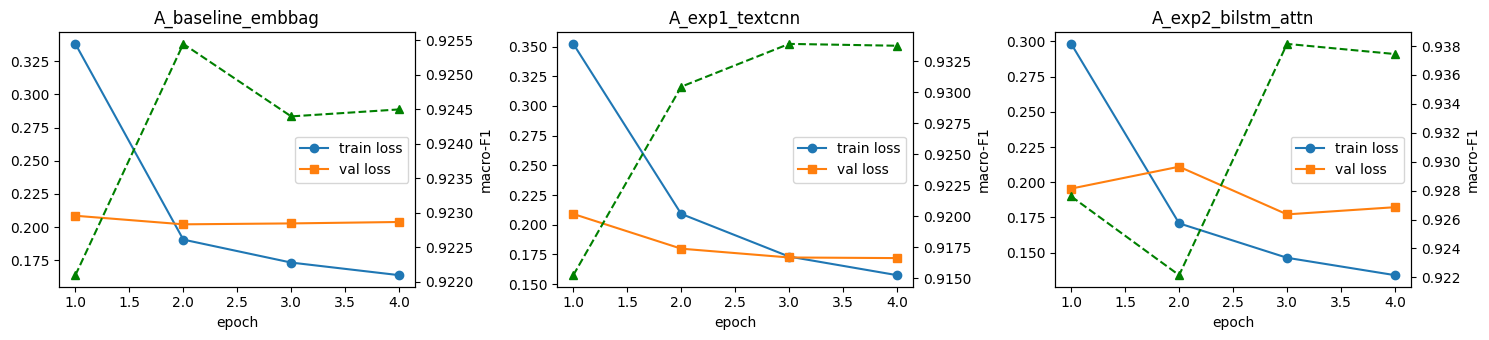

In [12]:
fig, axes = plt.subplots(1, len(RUNS), figsize=(5 * len(RUNS), 3.5))
for ax, (name, r) in zip(np.atleast_1d(axes), RUNS.items()):
    h = pd.DataFrame(r["hist"])
    ax.plot(h.epoch, h.train_loss, "o-", label="train loss"); ax.plot(h.epoch, h.val_loss, "s-", label="val loss")
    ax2 = ax.twinx(); ax2.plot(h.epoch, h.val_f1_macro, "g^--", label="val macro-F1"); ax2.set_ylabel("macro-F1")
    ax.set_title(name); ax.set_xlabel("epoch"); ax.legend(loc="center right")
plt.tight_layout(); plt.savefig(DIRS["outputs"] / "training_curves.png", dpi=120); plt.show()

## Evaluation on the official test set (shared `eval_task2.py`)
Metrics: accuracy; precision/recall/F1 (macro, micro, weighted); confusion matrix; ROC-AUC; PR-AUC; MCC;
Brier score; ECE; 95% bootstrap CIs (accuracy, macro-F1, MCC); paired McNemar (baseline vs each
experimental model); per-slice macro-F1 and error rate; parameter count, training time, examples/sec, peak memory.

In [13]:
base_name = next(n for n, r in RUNS.items() if r["spec"]["role"] == "baseline")
masks = E.slice_masks(test_df["text"].tolist())
rows, slice_rows, mc_rows = [], [], []
for name, r in RUNS.items():
    m = E.classification_metrics(yte_np, r["p"])
    m.update(E.bootstrap_ci(yte_np, r["p"], n_boot=E.N_BOOT, seed=SEED))
    m.update(r["info"])
    rows.append({"model": name, "role": r["spec"]["role"], "type": r["spec"]["type"], **m})
    for s in E.slice_metrics(yte_np, r["p"], masks):
        slice_rows.append({"model": name, **s})
    if name != base_name:
        mc_rows.append({"baseline": base_name, "compared_model": name, **E.mcnemar(yte_np, RUNS[base_name]["p"], r["p"])})

metrics_df = pd.DataFrame(rows)
slices_df = pd.DataFrame(slice_rows)
mcnemar_df = pd.DataFrame(mc_rows)
for mrow in mc_rows:   # also put the McNemar p-value into the wide table
    metrics_df.loc[metrics_df.model == mrow["compared_model"], "mcnemar_p_vs_baseline"] = mrow["p_value"]
metrics_df.to_csv(OUT_ROOT / "metrics_report.csv", index=False)
slices_df.to_csv(DIRS["outputs"] / "slice_metrics.csv", index=False)
mcnemar_df.to_csv(DIRS["outputs"] / "mcnemar.csv", index=False)

show = ["model", "accuracy", "accuracy_ci_low", "accuracy_ci_high", "f1_macro", "f1_macro_ci_low", "f1_macro_ci_high",
        "f1_micro", "f1_weighted", "precision_macro", "recall_macro", "roc_auc", "pr_auc", "mcc", "mcc_ci_low",
        "mcc_ci_high", "brier", "ece", "params", "train_time_s", "train_examples_per_s", "infer_examples_per_s", "peak_memory_mb"]
print(metrics_df[show].round(4).T.to_string())
print("\nMcNemar:\n", mcnemar_df.round(5).to_string(index=False))
print("\nSlices:\n", slices_df.pivot(index="slice", columns="model", values="f1_macro").round(4).to_string())

                                      0               1                   2
model                 A_baseline_embbag  A_exp1_textcnn  A_exp2_bilstm_attn
accuracy                         0.9289          0.9343              0.9425
accuracy_ci_low                  0.9264          0.9317              0.9402
accuracy_ci_high                 0.9312          0.9368              0.9449
f1_macro                         0.9289          0.9343              0.9425
f1_macro_ci_low                  0.9264          0.9317              0.9402
f1_macro_ci_high                 0.9312          0.9368              0.9449
f1_micro                         0.9289          0.9343              0.9425
f1_weighted                      0.9289          0.9343              0.9425
precision_macro                  0.9289          0.9343              0.9425
recall_macro                     0.9289          0.9343              0.9425
roc_auc                           0.978          0.9833              0.9865
pr_auc      

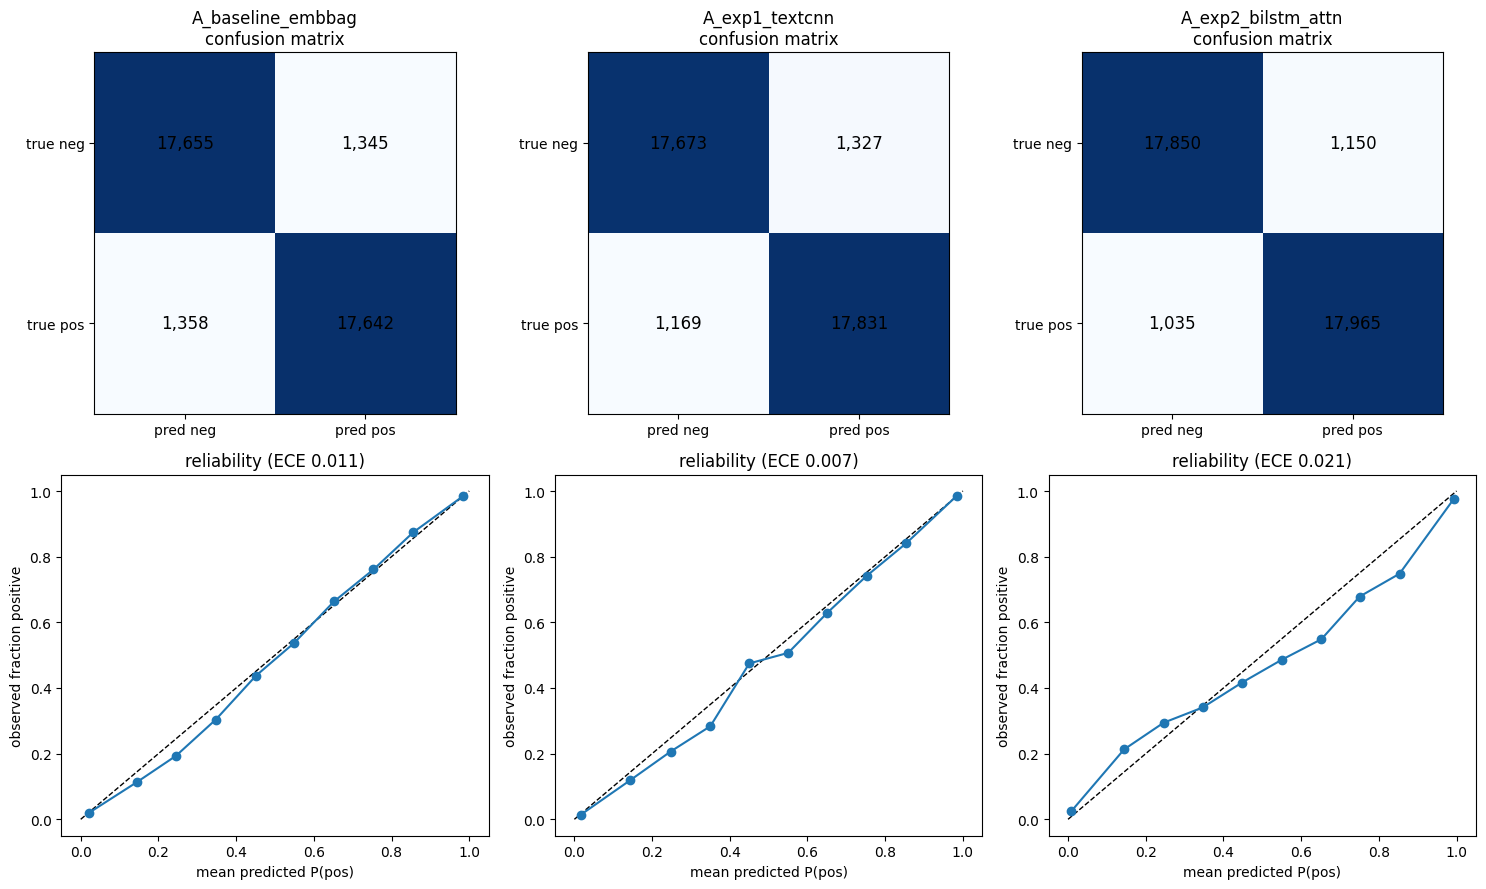

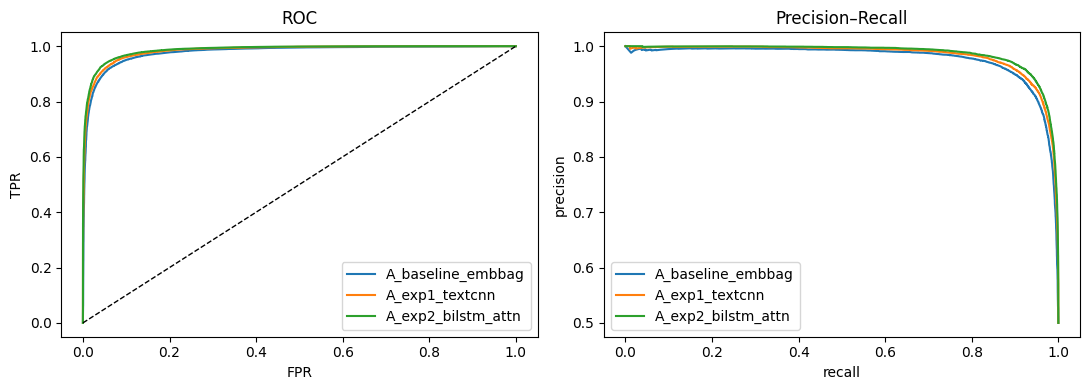

In [14]:
n = len(RUNS)
fig, ax = plt.subplots(2, n, figsize=(5 * n, 9))
ax = np.array(ax).reshape(2, n)
for j, (name, r) in enumerate(RUNS.items()):
    row = metrics_df.set_index("model").loc[name]
    cm = np.array([[row.tn, row.fp], [row.fn, row.tp]])
    ax[0, j].imshow(cm, cmap="Blues")
    for (a, b), v in np.ndenumerate(cm):
        ax[0, j].text(b, a, f"{v:,}", ha="center", va="center", fontsize=12)
    ax[0, j].set_xticks([0, 1], ["pred neg", "pred pos"]); ax[0, j].set_yticks([0, 1], ["true neg", "true pos"])
    ax[0, j].set_title(f"{name}\nconfusion matrix")
    rel = pd.DataFrame(E.reliability_table(yte_np, r["p"]))
    ax[1, j].plot([0, 1], [0, 1], "k--", lw=1); ax[1, j].plot(rel.mean_pred, rel.frac_pos, "o-")
    ax[1, j].set_xlabel("mean predicted P(pos)"); ax[1, j].set_ylabel("observed fraction positive")
    ax[1, j].set_title(f"reliability (ECE {row.ece:.3f})")
plt.tight_layout(); plt.savefig(DIRS["outputs"] / "confusion_and_calibration.png", dpi=120); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for name, r in RUNS.items():
    fpr, tpr, _ = roc_curve(yte_np, r["p"]); pr, rc, _ = precision_recall_curve(yte_np, r["p"])
    ax[0].plot(fpr, tpr, label=name); ax[1].plot(rc, pr, label=name)
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set_title("ROC"); ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR"); ax[0].legend()
ax[1].set_title("Precision–Recall"); ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision"); ax[1].legend()
plt.tight_layout(); plt.savefig(DIRS["outputs"] / "roc_pr_curves.png", dpi=120); plt.show()

## Error review — 20 errors of one model
The reviewed model is the experimental model with the best validation macro-F1 (or `review_model` in the config).
* 5 **confident false positives** (true negative, highest P(pos))
* 5 **confident false negatives** (true positive, lowest P(pos))
* 5 **near-threshold errors** (smallest |P − 0.5|)
* 5 **slice-specific failures** (most confident errors inside the slice with the highest error rate, n ≥ 50)

The notebook suggests an error type for each review with simple keyword heuristics. **These are only
suggestions.** Read each review, correct the type, and keep one *testable* fix in `failure_analysis.md`.

In [15]:
exp_runs = {n: r for n, r in RUNS.items() if r["spec"]["role"] != "baseline"}
REVIEW = CFG.get("review_model") or max(exp_runs, key=lambda n: exp_runs[n]["info"]["best_val_f1_macro"])
p = RUNS[REVIEW]["p"]
pred = (p >= 0.5).astype(int)
err = pred != yte_np
df_e = test_df.assign(p_pos=p, pred=pred, proc=[" ".join(t) for t in tok_te])

def guess_type(text, n_words):
    t = text.lower()
    if re.search(r"\b([1-5]|one|two|four|five)\s*stars?\b", t): return "possible label noise / star-rating mismatch"
    if E.CONTRAST_RE.search(t): return "mixed sentiment (contrast)"
    if re.search(r"\b(yeah right|thanks a lot|great job|oh great|lol|sure\b)", t) or t.count('"') >= 4: return "possible sarcasm"
    if E.NEG_RE.search(t): return "negation handling"
    if n_words <= 25: return "too little evidence (short review)"
    if n_words > 250: return "long review / truncation"
    return "unclear — check wording / domain terms"

picked = []
def take(frame, kind, k=5):
    for i, row in frame.iterrows():
        if len([x for x in picked if x[0] == kind]) >= k: break
        if i not in [x[1] for x in picked]:
            picked.append((kind, i))

take(df_e[err & (yte_np == 0)].sort_values("p_pos", ascending=False), "confident false positive")
take(df_e[err & (yte_np == 1)].sort_values("p_pos"), "confident false negative")
take(df_e[err].assign(d=(df_e.p_pos - 0.5).abs()).sort_values("d"), "near-threshold error")
sm = slices_df[(slices_df.model == REVIEW) & (slices_df.n >= 50)].sort_values("error_rate", ascending=False)
worst_slice = sm.iloc[0]["slice"]
in_slice = pd.Series(masks[worst_slice], index=df_e.index)
take(df_e[err & in_slice].assign(c=(df_e.p_pos - 0.5).abs()).sort_values("c", ascending=False), f"slice-specific ({worst_slice})")

rev = pd.DataFrame([{"category": k, "test_index": i, "true": int(df_e.loc[i, "label"]), "p_pos": round(float(df_e.loc[i, "p_pos"]), 4),
                     "n_words": int(df_e.loc[i, "n_words"]), "suggested_error_type": guess_type(df_e.loc[i, "text"], df_e.loc[i, "n_words"]),
                     "text": df_e.loc[i, "text"][:500]} for k, i in picked])
rev.to_csv(DIRS["outputs"] / "error_review_20.csv", index=False)
print(f"reviewed model: {REVIEW} | worst slice: {worst_slice}")
print(rev[["category", "true", "p_pos", "suggested_error_type"]].to_string())
print("\nerror-type counts (suggested):\n", rev.suggested_error_type.value_counts().to_string())

reviewed model: A_exp2_bilstm_attn | worst slice: has contrast word
                              category  true   p_pos                         suggested_error_type
0             confident false positive     0  1.0000       unclear — check wording / domain terms
1             confident false positive     0  0.9998                   mixed sentiment (contrast)
2             confident false positive     0  0.9997                            negation handling
3             confident false positive     0  0.9997                   mixed sentiment (contrast)
4             confident false positive     0  0.9996                   mixed sentiment (contrast)
5             confident false negative     1  0.0002                   mixed sentiment (contrast)
6             confident false negative     1  0.0002                            negation handling
7             confident false negative     1  0.0002  possible label noise / star-rating mismatch
8             confident false negative     1  0.00

In [16]:
FIXES = {
    "negation handling": "Mark negation scope in preprocessing (prefix tokens after not/no/never with NOT_ until the next clause) and retrain; test: error rate on the 'has negation' slice drops vs the current value, McNemar p < 0.05 on that slice.",
    "mixed sentiment (contrast)": "Weight the clause after 'but/however' (keep only text after the last contrast word as an extra input channel); test: macro-F1 on the 'has contrast word' slice improves by ≥ 1 point.",
    "long review / truncation": "Raise max_len (or use head+tail with a larger tail); test: error rate on the 'len > 250' slice decreases with no drop on short reviews.",
    "too little evidence (short review)": "Keep '!' and emoticons as tokens instead of deleting punctuation; test: error rate on the shortest-length slice decreases.",
    "possible sarcasm": "Keep punctuation/quote tokens and add a character-level CNN channel; test: re-score the sarcasm-tagged errors and the 'has !' slice.",
    "possible label noise / star-rating mismatch": "Relabel a 200-review audit sample to estimate label-noise rate; test: if > 2%, train with label smoothing 0.1 and compare Brier/ECE.",
    "unclear — check wording / domain terms": "Increase max_vocab / lower min_freq so rare domain words are not <unk>; test: test OOV rate and error rate on these reviews decrease.",
}
top_type = rev.suggested_error_type.value_counts().index[0]
lines = [f"# Task 2 — Error review ({MEMBER})", "",
         f"Reviewed model: **{REVIEW}** (checkpoint `{RUNS[REVIEW]['info']['checkpoint_id']}`), official test set, threshold 0.5.",
         f"Worst slice (n ≥ 50): **{worst_slice}**. Full table: `outputs/error_review_20.csv`.", "",
         "> The error types below were suggested by keyword heuristics — **verify each one by reading the review and edit the type/notes.**", ""]
for k in rev.category.unique():
    lines += [f"## {k}", "", "| # | true | P(pos) | error type | review (first 300 chars) | note |", "|---|---|---|---|---|---|"]
    for j, r in rev[rev.category == k].reset_index(drop=True).iterrows():
        txt = r.text[:300].replace("|", "/").replace("\n", " ")
        lines.append(f"| {j + 1} | {'pos' if r.true else 'neg'} | {r.p_pos:.3f} | {r.suggested_error_type} | {txt} | TODO |")
    lines.append("")
lines += ["## Error-type summary", "", *[f"* {t}: {c}" for t, c in rev.suggested_error_type.value_counts().items()], "",
          "## Proposed testable fix", "", f"Most frequent type: **{top_type}**.", "", FIXES.get(top_type, "TODO"), ""]
fa = OUT_ROOT / "failure_analysis.md"
if not fa.exists() or is_smoke():
    fa.write_text("\n".join(lines), encoding="utf-8")

## 2.3 Comparing this member's models

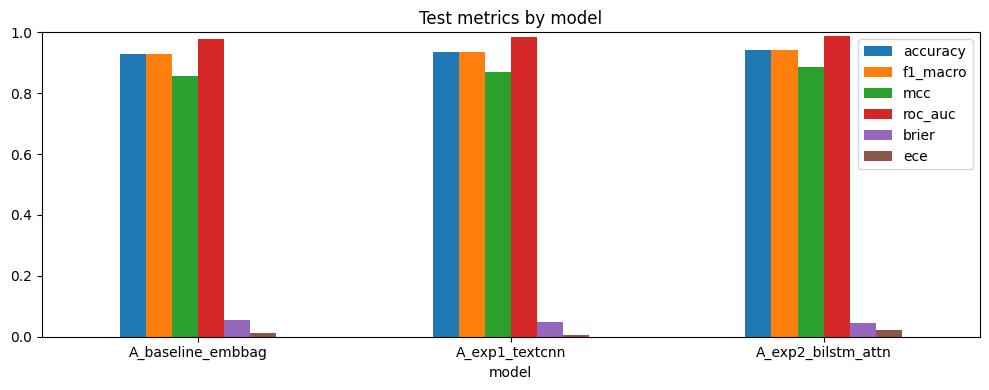

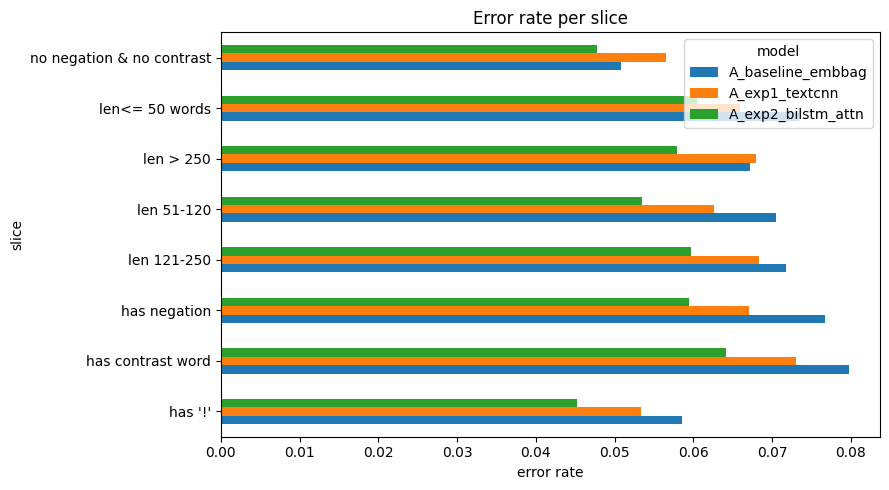

In [17]:
cmp_cols = ["accuracy", "f1_macro", "mcc", "roc_auc", "brier", "ece"]
metrics_df.set_index("model")[cmp_cols].plot.bar(figsize=(10, 4), rot=0, ylim=(max(0, metrics_df[cmp_cols].min().min() - 0.05), 1.0))
plt.title("Test metrics by model"); plt.tight_layout(); plt.savefig(DIRS["outputs"] / "model_comparison.png", dpi=120); plt.show()
sl = slices_df.pivot(index="slice", columns="model", values="error_rate")
sl.plot.barh(figsize=(9, 5)); plt.xlabel("error rate"); plt.title("Error rate per slice")
plt.tight_layout(); plt.savefig(DIRS["outputs"] / "slice_error_rates.png", dpi=120); plt.show()

In [18]:
def md_table(df):
    out = ["| " + " | ".join(map(str, df.columns)) + " |", "|" + "---|" * len(df.columns)]
    for _, r in df.iterrows():
        out.append("| " + " | ".join(f"{v:.4g}" if isinstance(v, (float, np.floating)) else str(v) for v in r.values) + " |")
    return "\n".join(out)

spec_rows = pd.DataFrame([{"model": s["name"], "role": s["role"], "type": s["type"],
                           "hyper-parameters": ", ".join(f"{k}={v}" for k, v in s.items() if k not in ("name", "role", "type", "why"))}
                          for s in CFG["models"]])
why = "\n".join(f"* **{s['name']}** — {s.get('why', 'TODO')}" for s in CFG["models"])
results = f"""# Task 2 — Yelp Polarity sentiment · {MEMBER} (lineup {CFG.get('lineup')})

## Data and preprocessing
Train subset {len(tr_part):,} / val {len(va_part):,} / official test {len(test_df):,} (seed {SEED}).
Preprocessing: {json.dumps(PC)}. Vocabulary {V:,} tokens built on the train subset only.

## Models
{md_table(spec_rows)}

## Why these models (architecture and embedding justification)
All embeddings are `nn.Embedding` layers trained from scratch (no pretrained vectors).
{why}

## Test metrics
{md_table(metrics_df[show].round(4))}

## Paired McNemar test (baseline = {base_name})
{md_table(mcnemar_df.round(5))}

## Per-slice macro-F1
{md_table(slices_df.pivot(index='slice', columns='model', values='f1_macro').round(4).reset_index())}

## Hardware (per model)
{md_table(metrics_df[['model', 'hardware', 'checkpoint_id']])}

## Evidence
Training curves `outputs/training_curves.png` · confusion matrices and calibration `outputs/confusion_and_calibration.png` ·
ROC/PR `outputs/roc_pr_curves.png` · slices `outputs/slice_metrics.csv` · error review `failure_analysis.md`,
`outputs/error_review_20.csv` · raw log `{log.path.relative_to(REPO_ROOT)}`.
"""
(OUT_ROOT / "results.md").write_text(results, encoding="utf-8")
man = write_manifest(REPO_ROOT, TASK, MEMBER, CFG, {n: OUT_ROOT / r["info"]["checkpoint"] for n, r in RUNS.items()},
                     [OUT_ROOT / "metrics_report.csv", OUT_ROOT / "results.md"], extra={"raw_log": str(log.path.relative_to(REPO_ROOT))})
log("wrote metrics_report.csv, results.md, failure_analysis.md, manifest:", man.relative_to(REPO_ROOT))
log.close()

wrote metrics_report.csv, results.md, failure_analysis.md, manifest: reproducibility/manifests/task2_sentiment_ruchika_chaurasia_20261002_000655.json
